#### Bar Plot --> both univariate & bivaraite ---> Categorical-Numerical 

In [71]:
import pandas as pd
import matplotlib.pyplot as plt 
df = pd.read_csv('student_depression_dataset.csv')

In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  str    
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  str    
 11  Dietary Habit

In [73]:
df['Dietary Habits'].value_counts()

Dietary Habits
Unhealthy    10317
Moderate      9921
Healthy       7651
Others          12
Name: count, dtype: int64

In [74]:
data=df[(df['Dietary Habits']=='Unhealthy') | (df['Dietary Habits']=='Healthy') | (df['Dietary Habits']=='Moderate')]
data['Dietary Habits'].value_counts()

Dietary Habits
Unhealthy    10317
Moderate      9921
Healthy       7651
Name: count, dtype: int64

In [75]:
d=data.groupby('Dietary Habits')['Depression'].sum()
d.value_counts()

Depression
3473    1
5558    1
7297    1
Name: count, dtype: int64

<BarContainer object of 3 artists>

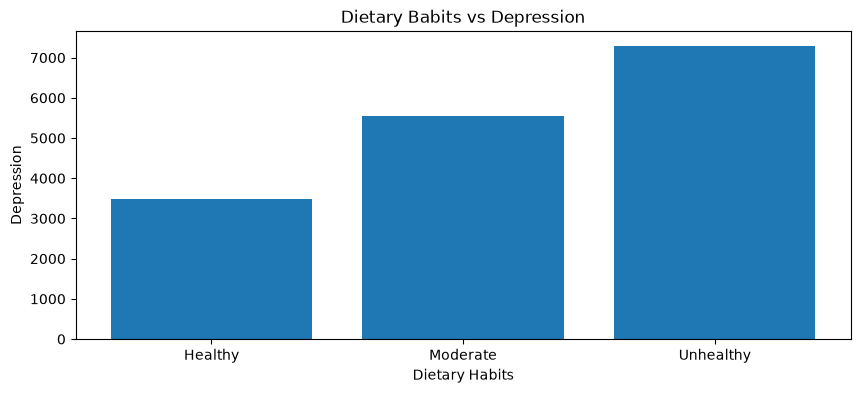

In [76]:
x=d.index
y=d.values
plt.figure(figsize=(10,4))
plt.title('Dietary Babits vs Depression')
plt.xlabel('Dietary Habits')
plt.ylabel('Depression')
plt.bar(x,y)

#### Horizontal Bar Chart --> when we have more number of bars on the x axis the labels of the bars gets overlapped,so we use the horizontal bar graph


<BarContainer object of 3 artists>

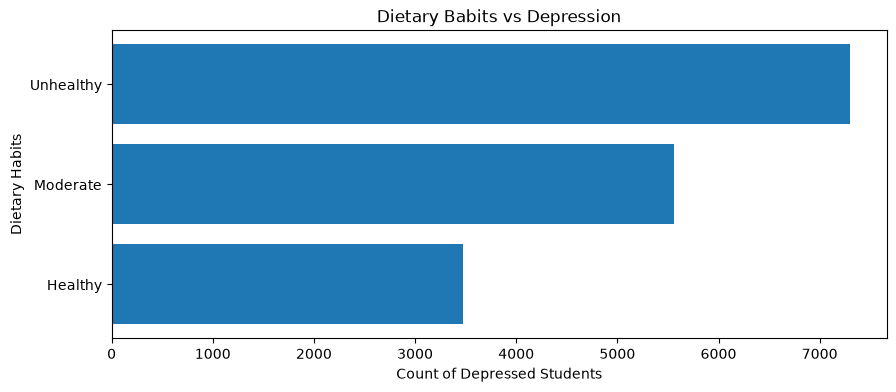

In [77]:
plt.figure(figsize=(10,4))
plt.title('Dietary Babits vs Depression')
plt.xlabel('Count of Depressed Students')
plt.ylabel('Dietary Habits')
plt.barh(x,y)

#### Multiple Bar Charts -> The Chart with multiple bars for a same category(for example:Multiple chocalate brand's sales in a Month)

In [78]:
sales=pd.read_csv('Chocolate Sales.csv')
sales.head(5)

,Sales Person,Country,Product,Date,Amount,Boxes Shipped
0,Jehu Rudeforth,UK,Mint Chip Choco,04-Jan-22,"$5,320",180
1,Van Tuxwell,India,85% Dark Bars,01-Aug-22,"$7,896",94
2,Gigi Bohling,India,Peanut Butter Cubes,07-Jul-22,"$4,501",91
3,Jan Morforth,Australia,Peanut Butter Cubes,27-Apr-22,"$12,726",342
4,Jehu Rudeforth,UK,Peanut Butter Cubes,24-Feb-22,"$13,685",184


In [79]:
sales['Amount'] = (
    sales['Amount']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
)
sales['Amount']=sales['Amount'].astype('int32')

In [80]:
sales['month'] = pd.to_datetime(sales['Date'], format='%d-%b-%y').dt.strftime('%B').str.lower()

In [81]:
m=sales[(sales['Product']=='Mint Chip Choco')]
d=sales[(sales['Product']=='85% Dark Bars')]
p=sales[(sales['Product']=='Peanut Butter Cubes')]


In [82]:
m=m.groupby('month')['Amount'].sum()
d=d.groupby('month')['Amount'].sum()
p=p.groupby('month')['Amount'].sum()

In [83]:
m.index=pd.CategoricalIndex(m.index,categories=['january','february','march','april','may','june','july','august'],ordered=True)
d.index=pd.CategoricalIndex(d.index,categories=['january','february','march','april','may','june','july','august'],ordered=True)
p.index=pd.CategoricalIndex(p.index,categories=['january','february','march','april','may','june','july','august'],ordered=True)

In [ ]:
m=m.sort_index()
d=d.sort_index()
p=p.sort_index()

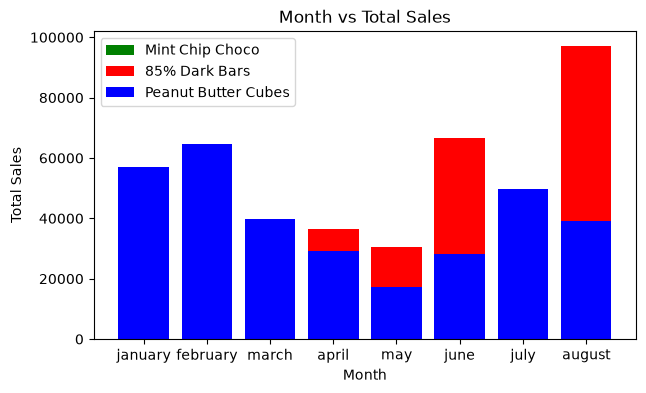

In [85]:
plt.figure(figsize=(7,4))
plt.title('Month vs Total Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.bar(m.index,m.values,width=0.8,color='green',label='Mint Chip Choco')
plt.bar(d.index,d.values,width=0.8,color='red',label='85% Dark Bars')
plt.bar(p.index,p.values,width=0.8,color='blue',label='Peanut Butter Cubes')
plt.legend()
plt.show()

#### In this multi bar graphs we see that green gets overlapped by dominating other brands based on their sales,so we want Equal Spacing for each Bar 
#### so we want np.arange() to split them 

In [86]:
import numpy as np

In [87]:
x=['january','february','march','april','may','june','july','august']

#### xticks is a function through which we can change the original labels into new labels 
#### xticks can also clear overlapping problem by a function (rotation='vertical')

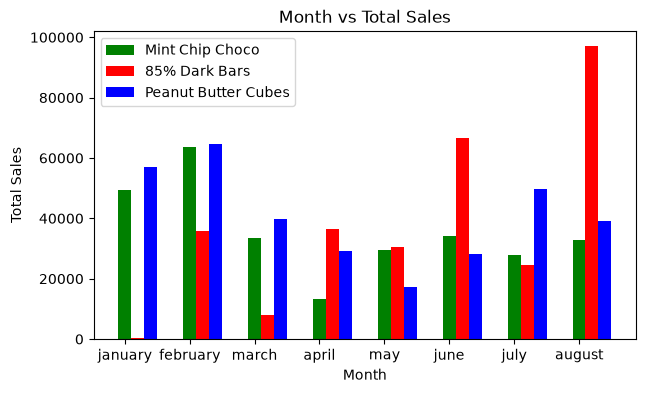

In [88]:
plt.figure(figsize=(7,4))
plt.title('Month vs Total Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.bar(np.arange(m.shape[0])-0.2,m.values,width=0.2,color='green',label='Mint Chip Choco')
plt.bar(np.arange(d.shape[0]),d.values,width=0.2,color='red',label='85% Dark Bars')
plt.bar(np.arange(p.shape[0])+0.2,p.values,width=0.2,color='blue',label='Peanut Butter Cubes')
plt.xticks(np.arange(m.shape[0])-0.2,x)
plt.legend()
plt.show()

#### stacked bar charts in which the bar are not kept side by side but kept one on the other 
#### based on the parameter called bottom and one label is differentiated with other by the values which makes the difference

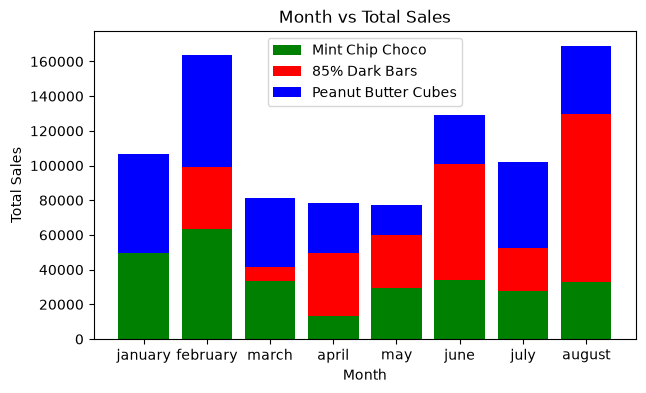

In [ ]:
plt.figure(figsize=(7,4))
plt.title('Month vs Total Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.bar(m.index,m.values,color='green',label='Mint Chip Choco',)
plt.bar(d.index,d.values,color='red',label='85% Dark Bars',bottom=m.values)
plt.bar(p.index,p.values,color='blue',label='Peanut Butter Cubes',bottom=(m.values+d.values))
plt.legend()
plt.show()

#### Histogram--> It is a kind of plot used for univariate analysis of a numerical column 
## Such that each column's values are split into specific bins of certain range 

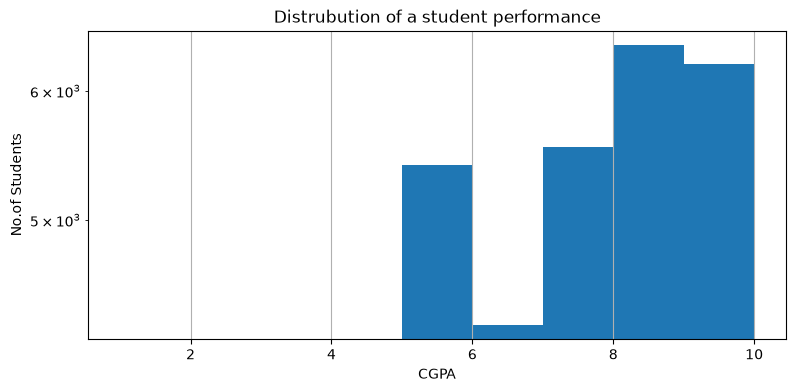

In [90]:
plt.figure(figsize=(9,4))
plt.title('Distrubution of a student performance')
plt.xlabel('CGPA')
plt.ylabel('No.of Students')
plt.hist(df['CGPA'],bins=[1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0],log=True)
plt.grid()
plt.show()

#### PieChart --> Through this we can do the percentage distrution of the Categorical column i.e Univariate Analysis and can also be used for bivariate analysis(Category-Numerical)

In [91]:
data=df['Dietary Habits'].value_counts()
data

Dietary Habits
Unhealthy    10317
Moderate      9921
Healthy       7651
Others          12
Name: count, dtype: int64

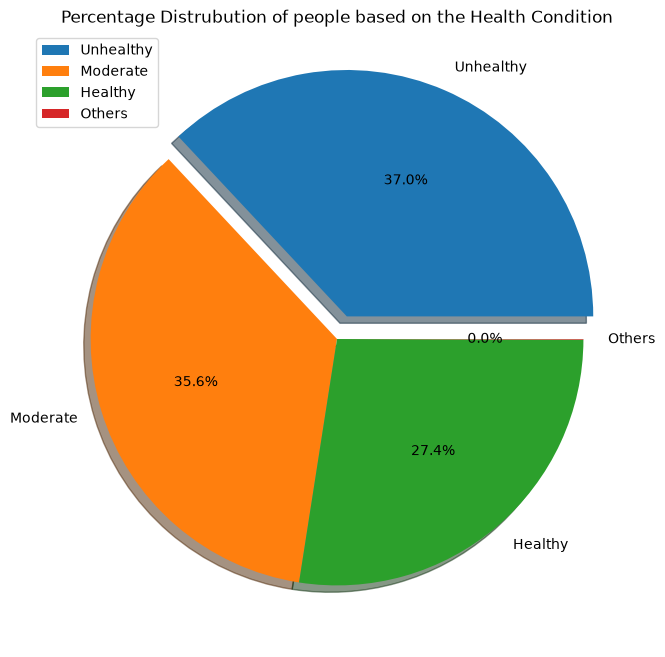

In [92]:
#Univariate Analysis
plt.figure(figsize=(12,8))
plt.title('Percentage Distrubution of people based on the Health Condition')
plt.pie(data,labels=data.index,autopct='%0.1f%%',explode=[0.1,0,0,0],shadow=True)
plt.legend()
plt.show()

In [95]:
data=sales.groupby('Country')['Amount'].sum()
data

Country
Australia      1137367
Canada          962899
India          1045800
New Zealand     950418
UK             1051792
USA            1035349
Name: Amount, dtype: int32

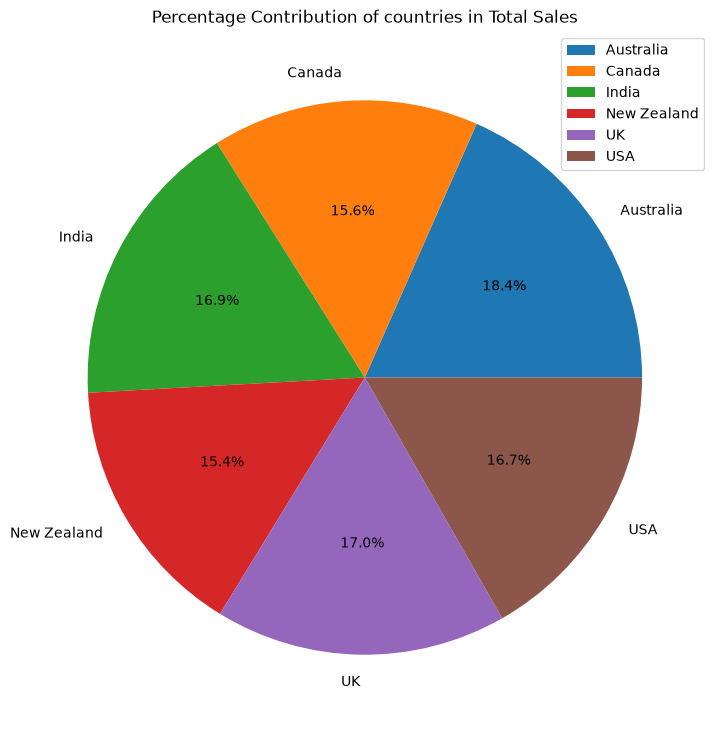

In [98]:
plt.figure(figsize=(12,9))
plt.title('Percentage Contribution of countries in Total Sales')
plt.pie(data,labels=data.index,autopct='%0.1f%%')
plt.legend()
plt.show()

In [99]:
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [105]:
plt.style.use('dark_background')

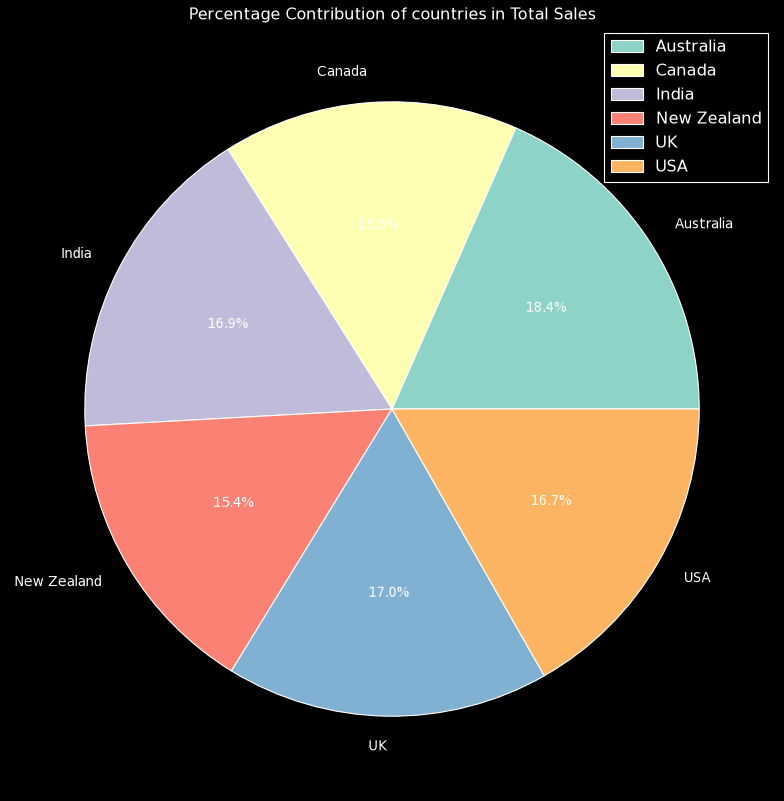

In [106]:
plt.figure(figsize=(14,12))
plt.title('Percentage Contribution of countries in Total Sales')
plt.pie(data,labels=data.index,autopct='%0.1f%%')
plt.legend()
plt.show()

#### to download this image to your laptop use plt.savefig('file_name.png')